# Wine Quality Prediction (Red Vinho Verde)

**Oasis Infobyte Internship | Data Analytics | Level 2, Task 2: Wine Quality Prediction**
**Intern:** Poleboina Kavya

**Goal:** predict how a wine will be rated by tasters, using only its chemical measurements (acidity, sugar, alcohol, sulphates and so on).

**Dataset:** Red Wine Quality (Cortez et al., 2009), UCI Machine Learning Repository / Kaggle. 1,599 red *Vinho Verde* wines from northern Portugal, 11 chemical features, and a quality score given by tasters.

**Models:** Random Forest, SGD Classifier and Support Vector Classifier (SVC), as the task requires.

**Plan:** inspect the data, explore it, deal with the class imbalance, choose how to group the quality scores, train the three models on a stratified split, compare them, and recommend one.

## 0. Setup
Import the libraries and fix a random seed (`RANDOM_STATE = 42`) so every run of this notebook gives the same results.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score, precision_score, recall_score)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
os.makedirs("screenshots", exist_ok=True)   # chart images are saved here
RANDOM_STATE = 42                            # fixed seed so results are reproducible

## 1. Load the data and inspect its structure

In [2]:
# sep=None lets pandas detect the separator, so both the Kaggle (comma) and UCI (semicolon) files load
df = pd.read_csv("winequality-red.csv", sep=None, engine="python")
print("Shape:", df.shape)
df.head()

Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
print("Column data types")
print(df.dtypes)
print("\nMissing values per column:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe().T.round(3)

Column data types
fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

Missing values per column: 0
Duplicate rows: 240


,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.320,1.741,4.600,7.100,7.900,9.200,15.900
volatile acidity,1599.0,0.528,0.179,0.120,0.390,0.520,0.640,1.580
citric acid,1599.0,0.271,0.195,0.000,0.090,0.260,0.420,1.000
residual sugar,1599.0,2.539,1.410,0.900,1.900,2.200,2.600,15.500
chlorides,1599.0,0.087,0.047,0.012,0.070,0.079,0.090,0.611
free sulfur dioxide,1599.0,15.875,10.460,1.000,7.000,14.000,21.000,72.000
total sulfur dioxide,1599.0,46.468,32.895,6.000,22.000,38.000,62.000,289.000
density,1599.0,0.997,0.002,0.990,0.996,0.997,0.998,1.004
pH,1599.0,3.311,0.154,2.740,3.210,3.310,3.400,4.010
sulphates,1599.0,0.658,0.170,0.330,0.550,0.620,0.730,2.000


**Observations**
- The file has **1,599 rows and 12 columns**: 11 chemical features (all `float64`) and the target `quality` (integer).
- There are **no missing values**, so no imputation is needed.
- There are **240 duplicate rows**. In wine data, two different wines can have identical measurements by chance, but with 11 decimal-valued features that many exact repeats are more likely repeated records. They matter for modelling, because a duplicate can land in both the training and the test set and make a model look better than it is. I handle them in section 5.
- The scales differ a lot. `total sulfur dioxide` reaches 289, while `density` stays between 0.990 and 1.004. This matters for SVC and SGD, which are sensitive to feature scale, so I standardise the features for those two models.

## 2. Class distribution of the quality score

         wines  percent
quality                
3           10      0.6
4           53      3.3
5          681     42.6
6          638     39.9
7          199     12.4
8           18      1.1


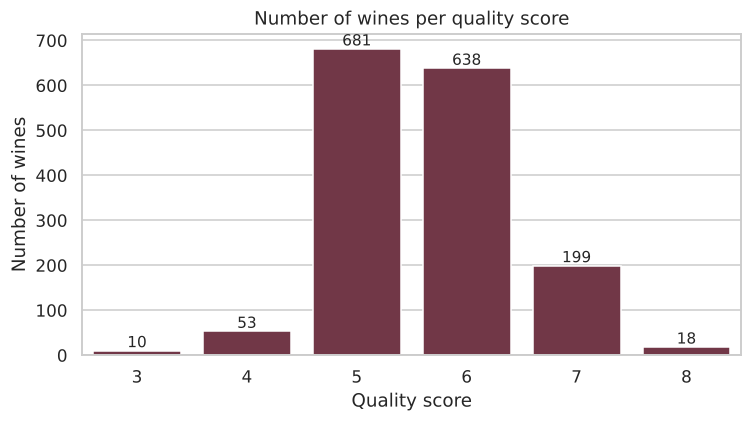

In [4]:
counts = df["quality"].value_counts().sort_index()
dist = pd.DataFrame({"wines": counts, "percent": (counts / len(df) * 100).round(1)})
print(dist)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(x=counts.index, y=counts.values, color="#7b2d43", ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 8, str(v), ha="center", fontsize=10)
ax.set_title("Number of wines per quality score")
ax.set_xlabel("Quality score")
ax.set_ylabel("Number of wines")
plt.tight_layout()
plt.savefig("screenshots/quality_distribution.png", bbox_inches="tight")
plt.show()

**Observations**
- Quality only takes six values, **3 to 8**, although the scale officially runs from 0 to 10. Nobody scored a wine below 3 or above 8.
- The distribution is a hump in the middle: score **5 has 681 wines (42.6%)** and score **6 has 638 (39.9%)**.
- The ends are tiny: score 3 has 10 wines (0.6%) and score 8 has 18 wines (1.1%). Excellent wines (7 and 8) are only **13.5%** of the data.

## 3. Exploratory data analysis

Skewness of each feature (0 = symmetric, above 1 = strongly right-skewed):
chlorides               5.68
residual sugar          4.54
sulphates               2.43
total sulfur dioxide    1.52
free sulfur dioxide     1.25
fixed acidity           0.98
alcohol                 0.86
volatile acidity        0.67
citric acid             0.32
pH                      0.19
density                 0.07
dtype: float64


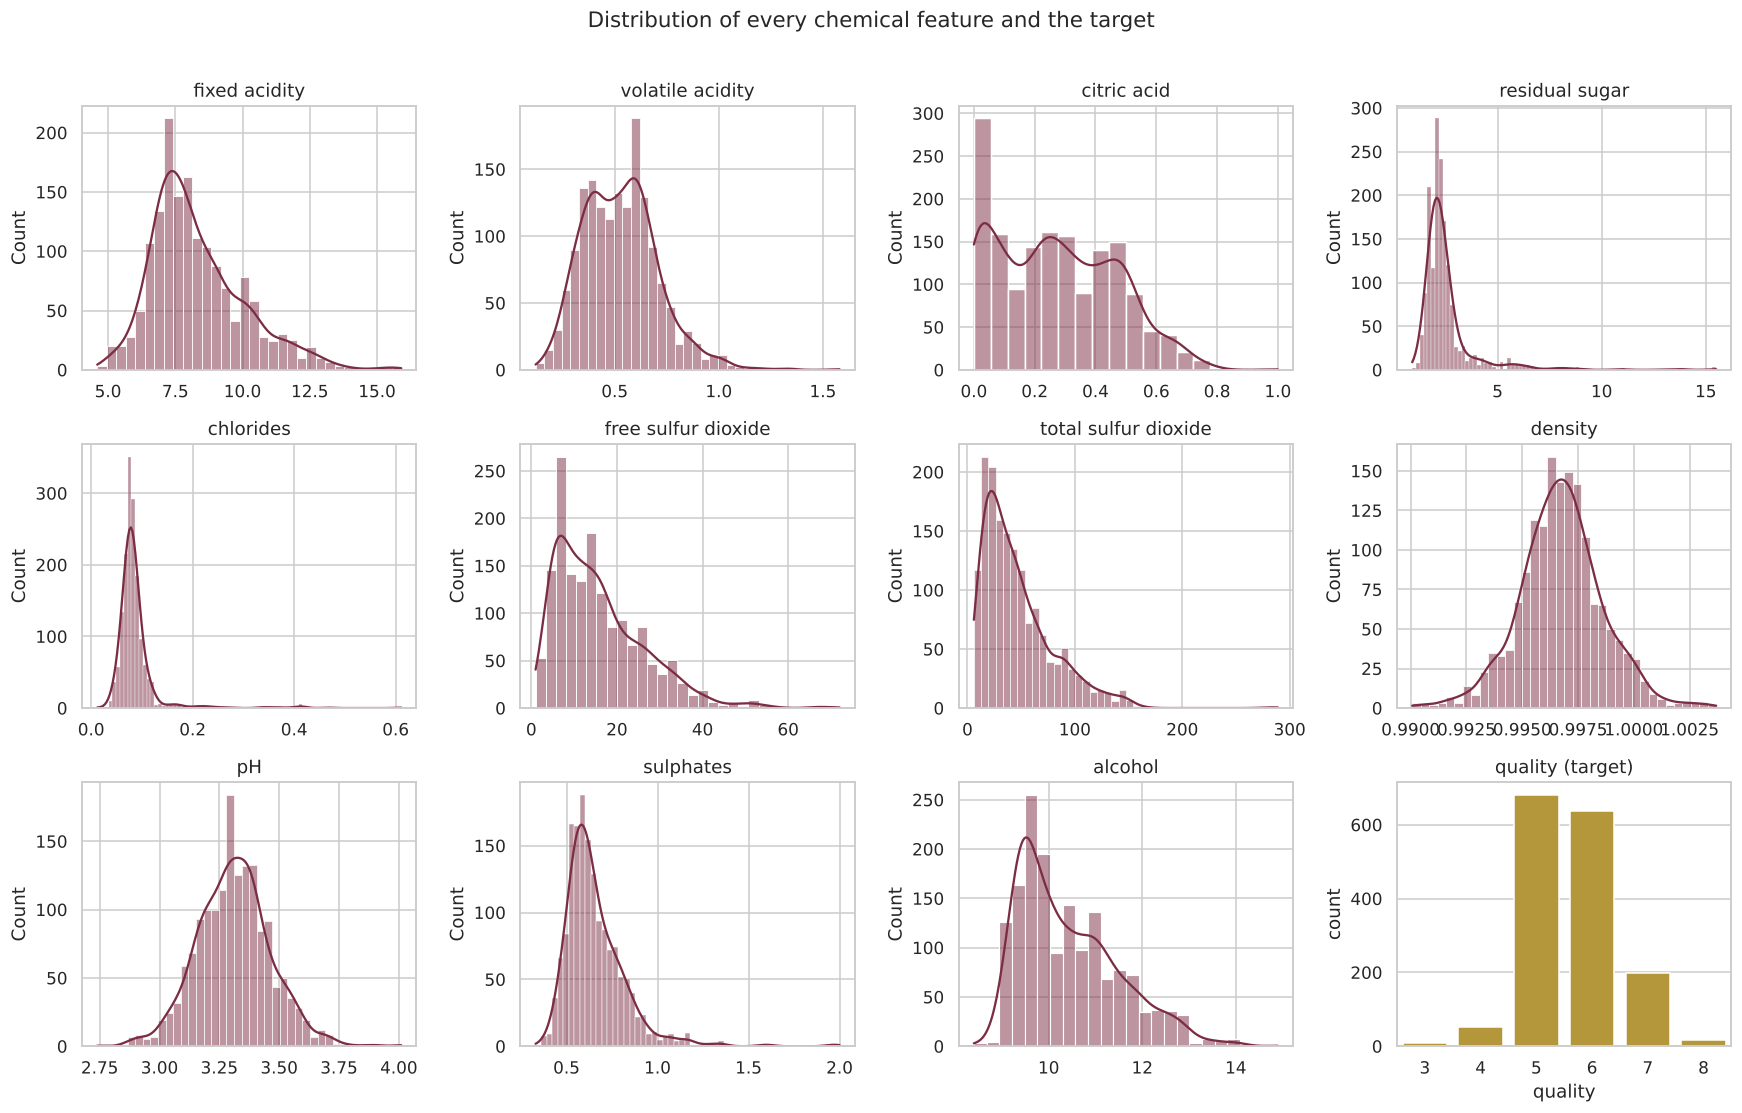

In [5]:
features = [c for c in df.columns if c != "quality"]

fig, axes = plt.subplots(3, 4, figsize=(16, 10))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(df[col], kde=True, ax=ax, color="#7b2d43")
    ax.set_title(col)
    ax.set_xlabel("")
sns.countplot(x="quality", data=df, ax=axes.ravel()[-1], color="#c9a227")
axes.ravel()[-1].set_title("quality (target)")
plt.suptitle("Distribution of every chemical feature and the target", y=1.01, fontsize=14)
plt.tight_layout()
plt.savefig("screenshots/feature_distributions.png", bbox_inches="tight")
plt.show()

print("Skewness of each feature (0 = symmetric, above 1 = strongly right-skewed):")
print(df[features].skew().sort_values(ascending=False).round(2))

**Observations (distributions)**
- `density` (skew 0.07) and `pH` (0.19) are close to a bell shape.
- Several features are strongly **right-skewed**: `chlorides` (5.68), `residual sugar` (4.54) and `sulphates` (2.43). Most wines have low values, and a few have very high ones. Those long tails are the outliers visible in the plots.
- I keep those extreme values. They are real measurements of real wines, and Random Forest is not affected by skew. SVC and SGD use standardised features, which reduces the effect of scale, although very large outliers can still influence them.

Correlation of each feature with quality:
alcohol                 0.476
sulphates               0.251
citric acid             0.226
fixed acidity           0.124
residual sugar          0.014
free sulfur dioxide    -0.051
pH                     -0.058
chlorides              -0.129
density                -0.175
total sulfur dioxide   -0.185
volatile acidity       -0.391
Name: quality, dtype: float64


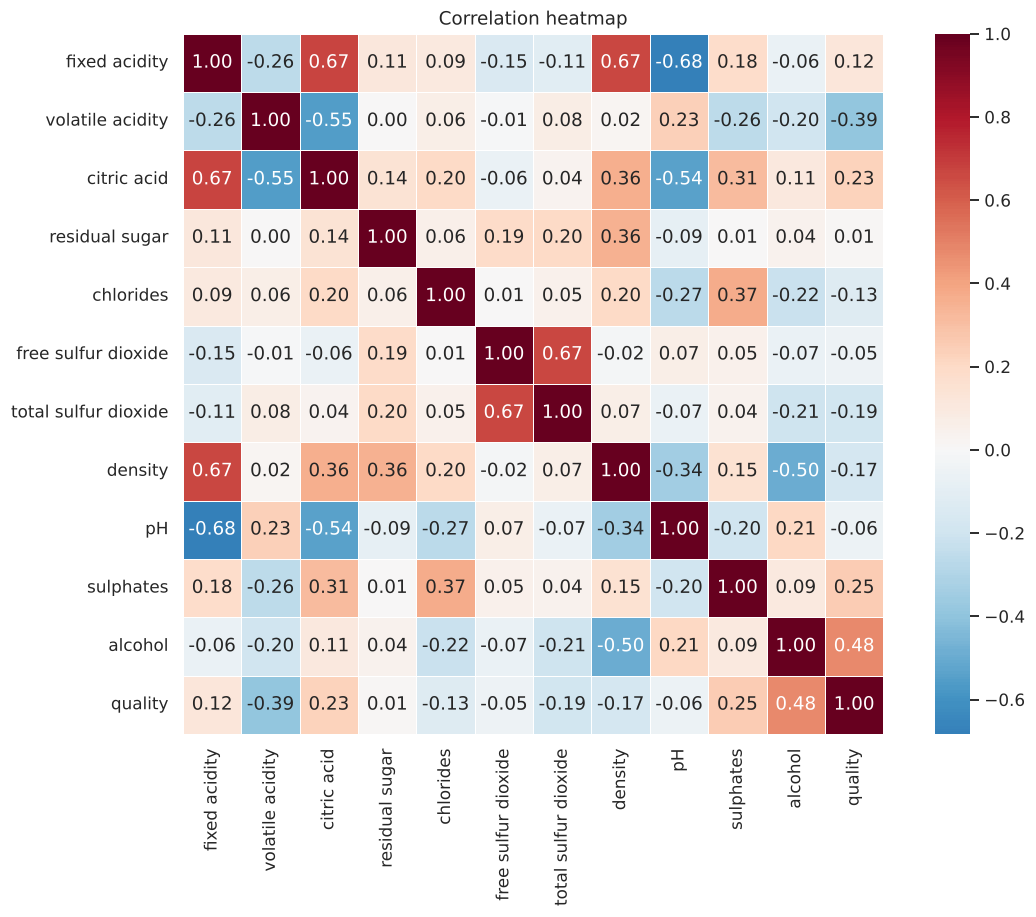

In [6]:
corr = df.corr()
plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, linewidths=0.5, square=True)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig("screenshots/correlation_heatmap.png", bbox_inches="tight")
plt.show()

print("Correlation of each feature with quality:")
print(corr["quality"].drop("quality").sort_values(ascending=False).round(3))

**Observations (correlations)**
- **Alcohol has the strongest link with quality (+0.48):** wines with more alcohol tend to be rated higher.
- **Volatile acidity is the strongest negative link (-0.39):** this is the acid that gives a vinegar smell, and tasters mark it down.
- `sulphates` (+0.25) and `citric acid` (+0.23) are weaker positive links. `total sulfur dioxide` (-0.19) and `density` (-0.18) are weak negative links.
- `residual sugar` (+0.01) and `free sulfur dioxide` (-0.05) have almost no linear relationship with quality.
- No single feature is strongly correlated with quality (the highest is 0.48), so predicting it will not be easy.
- Some features are correlated with each other: `fixed acidity` with `citric acid` (0.67), with `density` (0.67) and with `pH` (-0.68), and `free` with `total sulfur dioxide` (0.67). That is expected chemistry, since more acid means lower pH. It would cause trouble for a plain linear model, but the Random Forest handles it well.

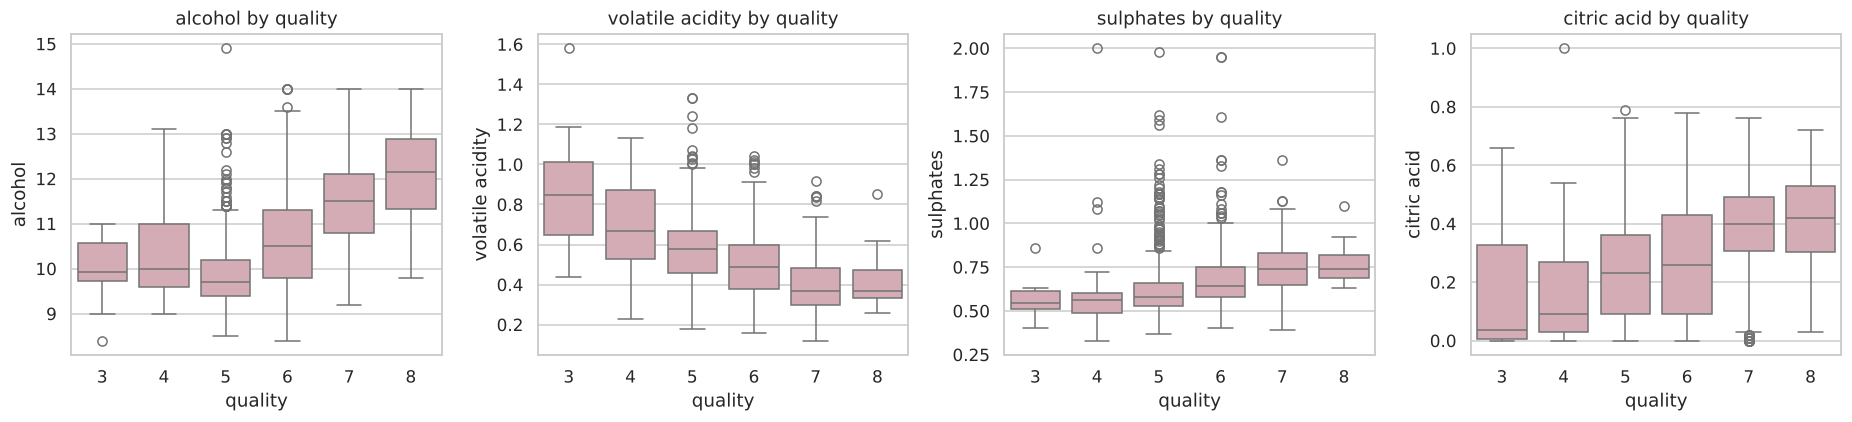

In [7]:
top = ["alcohol", "volatile acidity", "sulphates", "citric acid"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, col in zip(axes, top):
    sns.boxplot(x="quality", y=col, data=df, ax=ax, color="#d9a5b3")
    ax.set_title(f"{col} by quality")
plt.tight_layout()
plt.savefig("screenshots/top_features_by_quality.png", bbox_inches="tight")
plt.show()

**Observations (top four features by quality score)**
- Median alcohol rises from **9.7 for score 5 to 11.5 for score 7 and 12.15 for score 8**. Alcohol separates the best wines from the rest better than any other feature.
- Median volatile acidity falls steadily from **0.84 (score 3) to 0.37 (scores 7 and 8)**.
- Median sulphates rise from 0.58 (score 5) to 0.74 (scores 7 and 8), and median citric acid rises from 0.23 to 0.40-0.42.
- The pattern is clear in the medians, but the boxes overlap a lot between neighbouring scores. Wines of score 5 and 6 are hard to tell apart from chemistry alone, so I expect the models to struggle with the middle scores.

## 4. Class imbalance: what it is and how it affects modelling

In [8]:
majority = counts.max() / len(df) * 100
rare = counts[[3, 8]].sum()
print(f"Most common scores (5 and 6) together: {counts[[5, 6]].sum() / len(df) * 100:.1f}% of all wines")
print(f"Scores 3 and 8 together: {rare} wines ({rare / len(df) * 100:.1f}%)")
print(f"Largest class (score 5) is {counts[5] / counts[3]:.0f}x bigger than the smallest class (score 3)")

Most common scores (5 and 6) together: 82.5% of all wines
Scores 3 and 8 together: 28 wines (1.8%)
Largest class (score 5) is 68x bigger than the smallest class (score 3)


**Yes, the classes are strongly imbalanced.**
- Scores 5 and 6 make up **82.5%** of the wines. Scores 3 and 8 together are only 28 wines (**1.8%**). The biggest class is **68 times** larger than the smallest.

**How this affects modelling**
1. **Accuracy becomes misleading.** A model that always predicts the common class gets a high accuracy while learning nothing. I measure this with a baseline model in section 7.
2. **Models learn the common classes first.** The rare scores (3, 4, 8) have so few examples that a model sees almost nothing to learn from.
3. **A random split can go wrong.** With only 10 wines of score 3, an ordinary split might put none in the test set. That is why I split with **stratification**.
4. **Remedies I use:** `class_weight="balanced"` (rare classes count more during training), stratified splitting, and metrics that look at each class separately (precision, recall, F1) rather than accuracy alone.

## 5. Feature engineering: remove duplicates and group the quality scores

**Duplicates.** I remove the 240 duplicate rows before splitting, so that the same wine cannot appear in both the training set and the test set.

**Grouping the target.** The task suggests either a binary (good/bad) or a 3-class (low/medium/high) target. I choose **binary: `Good` = quality 7 or 8, `Not good` = quality 3 to 6.** My reasons:
- With 6 separate scores, the rare ones have 10 to 53 wines. Fewer classes give every class enough examples.
- A 3-class split (low = 3-4, medium = 5-6, high = 7-8) would leave only about 63 low-quality wines, and roughly 13 of them in the test set, which is too few to judge a model fairly.
- Finding the wines that stand out as good is also the most useful business question: it is what a producer or buyer wants to know.
- Scores 5 and 6 are hard to separate (see the boxplots), and the binary grouping avoids asking the models to do that.

In [9]:
n_before = len(df)
df_model = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {n_before} | duplicates removed: {n_before - len(df_model)} | rows after: {len(df_model)}")

# Binary target: Good wine = quality 7 or 8
df_model["label"] = np.where(df_model["quality"] >= 7, "Good", "Not good")
label_counts = df_model["label"].value_counts()
print()
print(pd.DataFrame({"wines": label_counts, "percent": (label_counts / len(df_model) * 100).round(1)}))
print("\nQuality scores inside each label:")
print(pd.crosstab(df_model["quality"], df_model["label"]))

Rows before: 1599 | duplicates removed: 240 | rows after: 1359

          wines  percent
label                   
Not good   1175     86.5
Good        184     13.5

Quality scores inside each label:
label    Good  Not good
quality                
3           0        10
4           0        53
5           0       577
6           0       535
7         167         0
8          17         0


**Observations**
- After removing duplicates there are **1,359 wines**.
- **184 wines (13.5%) are `Good`** and 1,175 (86.5%) are `Not good`. This is still imbalanced, but with enough `Good` wines to learn from.
- The crosstab confirms the grouping is clean: all of scores 7 and 8 are `Good`, and all of scores 3 to 6 are `Not good`.

In [10]:
X = df_model[features]
y = (df_model["label"] == "Good").astype(int)      # 1 = Good, 0 = Not good

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

split = pd.DataFrame({
    "rows": [len(y_train), len(y_test)],
    "Good wines": [y_train.sum(), y_test.sum()],
    "% Good": [round(y_train.mean() * 100, 1), round(y_test.mean() * 100, 1)]},
    index=["train", "test"])
split

,rows,Good wines,% Good
train,1087,147,13.5
test,272,37,13.6


**Observations**
- The split is **80% train (1,087 wines) and 20% test (272 wines)**, using `stratify=y`.
- Both sets keep the same share of `Good` wines (13.5% and 13.6%), so the test set is a fair copy of the whole data.
- The test set has only **37 good wines**. Because that number is small, one extra wine classified correctly moves recall by about 2.7 points, so I also use 5-fold cross-validation in section 10 to check that the ranking is stable.

## 6. Train the three classifiers

| Model | Why it fits this problem | Scaling needed? |
|---|---|---|
| **Random Forest** | Many decision trees voting together. Handles skewed features, correlated features and non-linear patterns. | No |
| **SGD Classifier** | A linear model trained with stochastic gradient descent. Very fast, a good simple baseline. | Yes |
| **SVC (RBF kernel)** | Finds a curved boundary between the classes. Often strong on small, clean tables. | Yes |

All three use `class_weight="balanced"` to handle the imbalance. For SGD and SVC, a `StandardScaler` is placed in a pipeline, so it is fitted on the training data only and does not leak information from the test set. I also train a **baseline** that always predicts `Not good`, to see what accuracy does for free.

In [11]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                            random_state=RANDOM_STATE, n_jobs=-1),
    "SGD Classifier": make_pipeline(StandardScaler(),
                                    SGDClassifier(loss="log_loss", class_weight="balanced",
                                                  max_iter=2000, random_state=RANDOM_STATE)),
    "SVC (RBF kernel)": make_pipeline(StandardScaler(),
                                      SVC(kernel="rbf", class_weight="balanced",
                                          random_state=RANDOM_STATE)),
}

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base_acc = accuracy_score(y_test, baseline.predict(X_test))
print(f"Baseline: always predict 'Not good' -> accuracy {base_acc:.3f}")

predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions[name] = model.predict(X_test)
    print(f"{name:18s} test accuracy: {accuracy_score(y_test, predictions[name]):.3f}")

Baseline: always predict 'Not good' -> accuracy 0.864
Random Forest      test accuracy: 0.875
SGD Classifier     test accuracy: 0.717
SVC (RBF kernel)   test accuracy: 0.805


**Observations**
- The baseline that never finds a single good wine scores **86.4% accuracy**.
- Random Forest reaches 87.5%, which is **only 1.1 points above the baseline**. SVC (80.5%) and SGD (71.7%) are actually *below* it.
- This is why I do not rank the models by accuracy. The classification reports in the next section show what happens to the `Good` wines, which is the class that matters.

## 7. Evaluate each model: accuracy, classification report, confusion matrix

In [12]:
target_names = ["Not good", "Good"]
for name in models:
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, predictions[name], target_names=target_names, digits=3))

Random Forest
              precision    recall  f1-score   support

    Not good      0.931     0.923     0.927       235
        Good      0.538     0.568     0.553        37

    accuracy                          0.875       272
   macro avg      0.735     0.745     0.740       272
weighted avg      0.878     0.875     0.876       272

SGD Classifier
              precision    recall  f1-score   support

    Not good      0.970     0.694     0.809       235
        Good      0.308     0.865     0.454        37

    accuracy                          0.717       272
   macro avg      0.639     0.779     0.631       272
weighted avg      0.880     0.717     0.761       272

SVC (RBF kernel)
              precision    recall  f1-score   support

    Not good      0.960     0.809     0.878       235
        Good      0.392     0.784     0.523        37

    accuracy                          0.805       272
   macro avg      0.676     0.796     0.700       272
weighted avg      0.882     

Random Forest      caught 21 of 37 good wines, wrongly flagged 18 ordinary wines as good
SGD Classifier     caught 32 of 37 good wines, wrongly flagged 72 ordinary wines as good
SVC (RBF kernel)   caught 29 of 37 good wines, wrongly flagged 45 ordinary wines as good


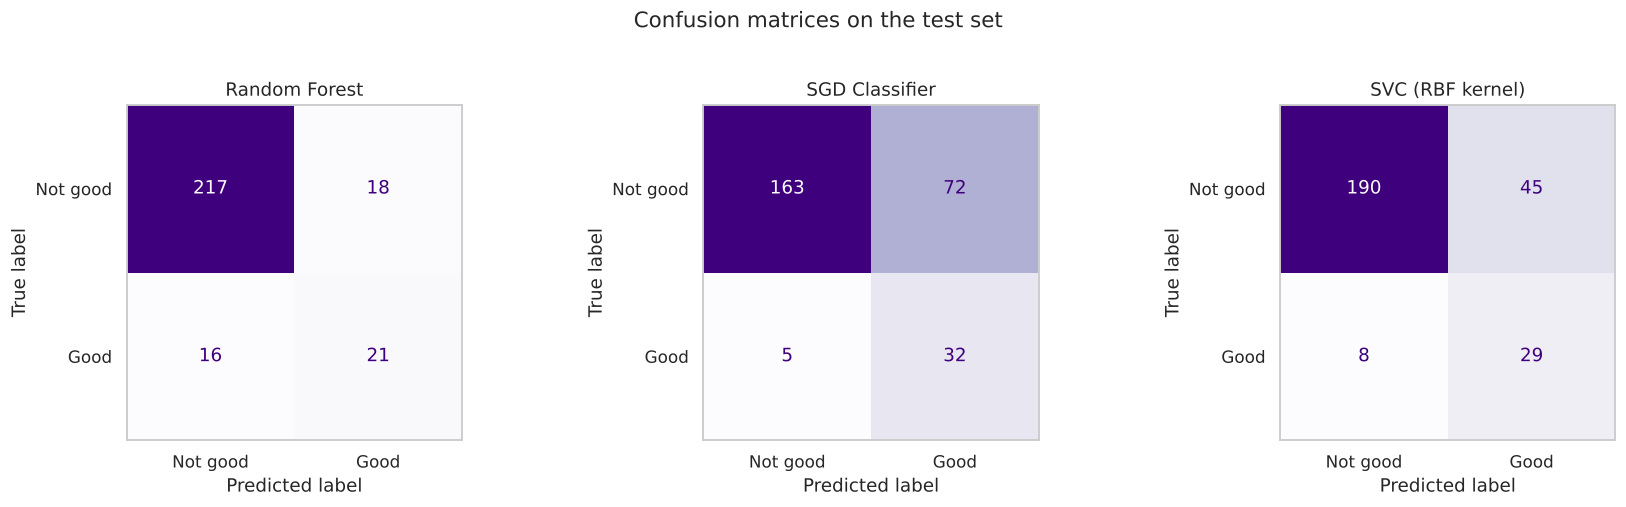

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, name in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name], display_labels=target_names,
        cmap="Purples", colorbar=False, ax=ax)
    ax.set_title(name)
    ax.grid(False)
plt.suptitle("Confusion matrices on the test set", y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig("screenshots/confusion_matrices.png", bbox_inches="tight")
plt.show()

for name in models:
    tn, fp, fn, tp = confusion_matrix(y_test, predictions[name]).ravel()
    print(f"{name:18s} caught {tp} of {tp + fn} good wines, wrongly flagged {fp} ordinary wines as good")

**Observations**

| Model | Good wines found (recall) | Share of "Good" predictions that are right (precision) | F1 (Good) |
|---|---|---|---|
| Random Forest | 21 of 37 (56.8%) | 53.8% | 0.553 |
| SVC | 29 of 37 (78.4%) | 39.2% | 0.523 |
| SGD | 32 of 37 (86.5%) | 30.8% | 0.454 |

- The three models make **different trade-offs**. SGD finds the most good wines (32 of 37) but raises 72 false alarms, so only about 3 in 10 of its "Good" predictions are right. Random Forest is the most careful: 18 false alarms, but it misses 16 good wines.
- **Random Forest has the best balance**: the highest F1 for `Good` (0.553) and the highest macro F1 (0.740).
- All models find "Not good" wines easily (F1 0.81 to 0.93). The hard part is the rare `Good` class, as expected from section 4.
- The confusion matrices show the same story as the table: the dark top-left cell is large for all models, and the models differ in how they split the errors between the two off-diagonal cells.

## 8. Feature importance (Random Forest)

alcohol                 0.222
sulphates               0.145
volatile acidity        0.102
citric acid             0.096
total sulfur dioxide    0.078
density                 0.073
fixed acidity           0.072
chlorides               0.064
pH                      0.058
free sulfur dioxide     0.051
residual sugar          0.040
dtype: float64


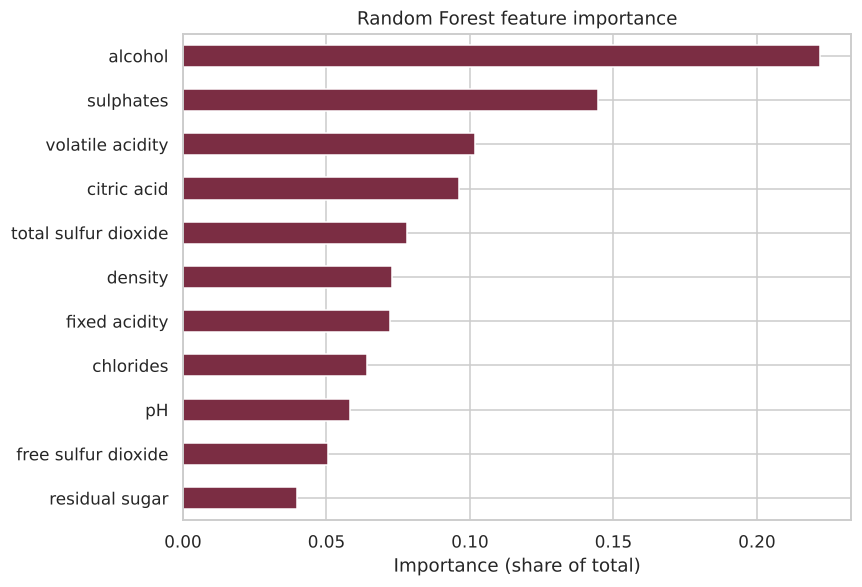

In [14]:
rf = models["Random Forest"]
importance = pd.Series(rf.feature_importances_, index=features).sort_values()

plt.figure(figsize=(8, 5.5))
importance.plot(kind="barh", color="#7b2d43")
plt.title("Random Forest feature importance")
plt.xlabel("Importance (share of total)")
plt.tight_layout()
plt.savefig("screenshots/feature_importance.png", bbox_inches="tight")
plt.show()

print(importance.sort_values(ascending=False).round(3))

**Observations**
- **Alcohol is the most important feature (0.222)**, followed by **sulphates (0.145)** and **volatile acidity (0.102)**. These three together account for about 47% of the total importance.
- This agrees with the correlation analysis: the same features that correlated most with quality are the ones the forest relies on.
- `residual sugar` (0.040) and `free sulfur dioxide` (0.051) matter least, again matching their near-zero correlations.
- Importance is spread over many features. No single measurement decides quality, and that is why a model using all 11 does better than a rule based on alcohol alone.
- Caution: impurity-based importance can favour features with many distinct values, and it splits credit between correlated features. It tells us what the model used, not what causes a wine to taste good.

## 9. Comparison table: all three models side by side

The table combines the **test-set** results with **5-fold stratified cross-validation** on the full data. Cross-validation repeats the evaluation on five different splits, so it is less affected by the luck of one small test set. `5-fold F1 std` shows how much the score moves between folds.

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows = []
for name, model in models.items():
    p = predictions[name]
    scores = cross_validate(model, X, y, cv=cv, scoring=["accuracy", "f1", "f1_macro"])
    rows.append({
        "Model": name,
        "Test accuracy": accuracy_score(y_test, p),
        "Precision (Good)": precision_score(y_test, p),
        "Recall (Good)": recall_score(y_test, p),
        "F1 (Good)": f1_score(y_test, p),
        "Macro F1": f1_score(y_test, p, average="macro"),
        "5-fold F1 (Good)": scores["test_f1"].mean(),
        "5-fold F1 std": scores["test_f1"].std(),
    })
comparison = pd.DataFrame(rows).set_index("Model").round(3)
comparison.sort_values("5-fold F1 (Good)", ascending=False)

,Test accuracy,Precision (Good),Recall (Good),F1 (Good),Macro F1,5-fold F1 (Good),5-fold F1 std
Model,,,,,,,
Random Forest,0.875,0.538,0.568,0.553,0.740,0.537,0.062
SVC (RBF kernel),0.805,0.392,0.784,0.523,0.700,0.522,0.035
SGD Classifier,0.717,0.308,0.865,0.454,0.631,0.413,0.076


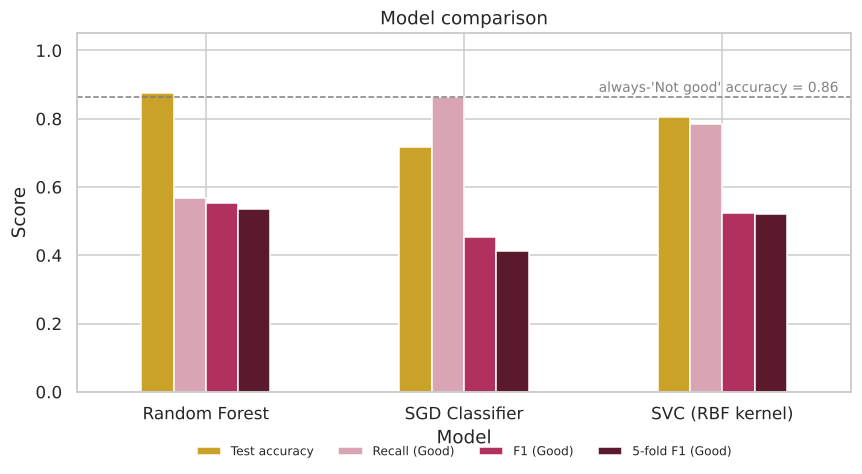

In [16]:
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_df = comparison[["Test accuracy", "Recall (Good)", "F1 (Good)", "5-fold F1 (Good)"]]
plot_df.plot(kind="bar", ax=ax, color=["#c9a227", "#d9a5b3", "#b03060", "#5b1a2b"], edgecolor="white")
ax.axhline(base_acc, color="grey", linestyle="--", linewidth=1)
ax.text(2.45, base_acc + 0.015, f"always-'Not good' accuracy = {base_acc:.2f}", ha="right", fontsize=9, color="grey")
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Model comparison")
plt.xticks(rotation=0)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=4, fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig("screenshots/model_comparison.png", bbox_inches="tight")
plt.show()

**Observations**
- **Random Forest is first** on test accuracy (0.875), F1 for `Good` (0.553), macro F1 (0.740) and 5-fold F1 (0.537).
- **SVC is a close second** (5-fold F1 0.522). The gap to Random Forest (0.015) is smaller than the fold-to-fold variation of Random Forest (0.062), so I cannot say SVC is truly worse on F1. SVC's advantage is higher recall (0.784 against 0.568).
- **SGD is clearly last** (5-fold F1 0.413). A linear boundary is too simple for this data.
- Even the best model is far from perfect: it finds about 57% of the good wines. Taster scores are subjective, and 11 chemical measurements cannot capture everything about taste, so there is a ceiling on what any model can do here.

In [17]:
out = df_model.copy()
out.to_csv("wine_quality_processed.csv", index=False)
print("Saved wine_quality_processed.csv with", out.shape[0], "rows and", out.shape[1], "columns")

Saved wine_quality_processed.csv with 1359 rows and 13 columns


## 10. Conclusion

**Which model is most suitable for deployment? Random Forest.**

Why:
1. **Best balance on the class that matters.** It has the highest F1 for `Good` wines on the test set and in cross-validation, and the highest macro F1.
2. **The only model that beats the baseline.** It is the only one above the 86.4% accuracy of "always predict Not good", so it is the only one whose predictions are right more often than the baseline.
3. **Fewer false alarms.** 18 wines wrongly called good, against 45 for SVC and 72 for SGD.
4. **Practical advantages.** It needs no feature scaling, copes with the skewed and correlated features, and gives feature importances that a winemaker can read.

**When I would choose differently.** If the aim is a first screen that must not miss any good wine, and a human will taste the shortlist afterwards, **SVC** is the better choice, because it finds 29 of 37 good wines against 21 for Random Forest. The right model depends on the cost of a missed wine against the cost of a false alarm.

**What the data says about wine.** Higher **alcohol**, higher **sulphates** and lower **volatile acidity** go with better ratings. Residual sugar barely matters.

**Limitations and next steps**
- The test set has only 37 good wines, so the scores have wide error bars (see the fold-to-fold spread).
- I used default-style settings. Tuning hyper-parameters (for example `GridSearchCV` on the Random Forest and the SVC's `C` and `gamma`) and oversampling methods such as SMOTE are the next things to try.
- Quality is a human opinion, and the data covers only red Vinho Verde from one region. The results should not be assumed to carry over to white wine or other regions.

**Files created by this notebook:** `wine_quality_processed.csv` (cleaned data with the Good / Not good label) and the charts in `screenshots/`.